In [ ]:
# Parametic experiments on gradient descent

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Running experiments

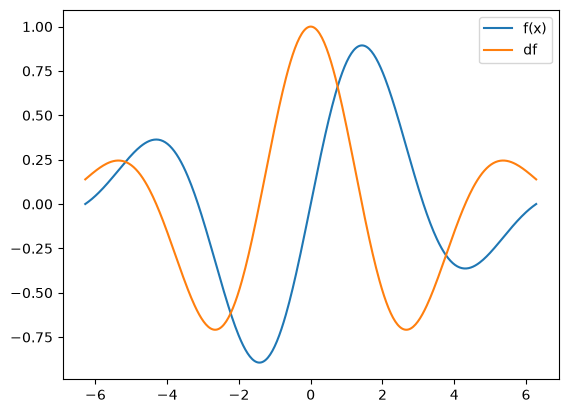

In [10]:
# Set up the function to study

x =np.linspace(-2*np.pi,2*np.pi,401)
fx = np.sin(x) * np.exp(-x**2*.05)

# Derivative of fx
df = np.cos(x)*np.exp(-x**2*.05) + np.sin(x)*(-.1*x)*np.exp(-x**2*.05)

# Plot functions

plt.plot(x,fx,x,df)
plt.legend(['f(x)','df'])
plt.show()

In [11]:
# Create iterable python functions

def f_fx(x):
    return np.sin(x) * np.exp(-x**2*.05)

def f_dx(x):
    return np.cos(x)*np.exp(-x**2*.05) + np.sin(x)*(-.1*x)*np.exp(-x**2*.05)

Starting point, localmin: [-0.4712389]


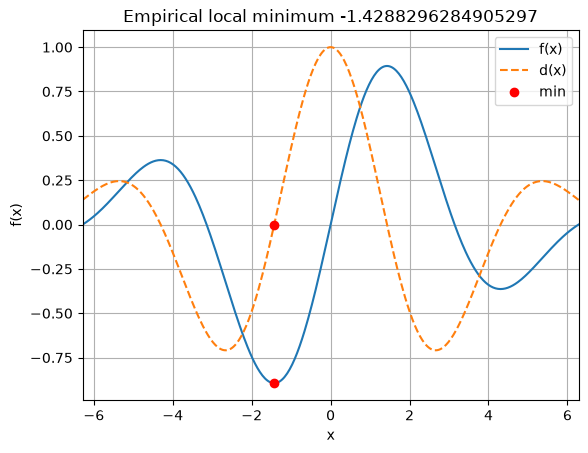

In [34]:
# Select random starting point

localmin = np.random.choice(x,1)

print("Starting point, localmin:",localmin)

# Set up parameters

learning_rate = 0.01
training_epochs = 1000

# Run training function

for i in range(training_epochs):
    grad = f_dx(localmin)
    localmin = localmin - learning_rate*grad

# Ploy results
plt.plot(x,f_fx(x),x,f_dx(x),'--')
plt.plot(localmin, f_dx(localmin),'ro')
plt.plot(localmin, f_fx(localmin),'ro')

plt.xlim(x[[0,-1]])
plt.grid()
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend(['f(x)','d(x)','min'])

plt.title("Empirical local minimum %s"%localmin[0])

plt.show()

# Run parametric experiments

## Experiment 1: Ststematically vary the starting location

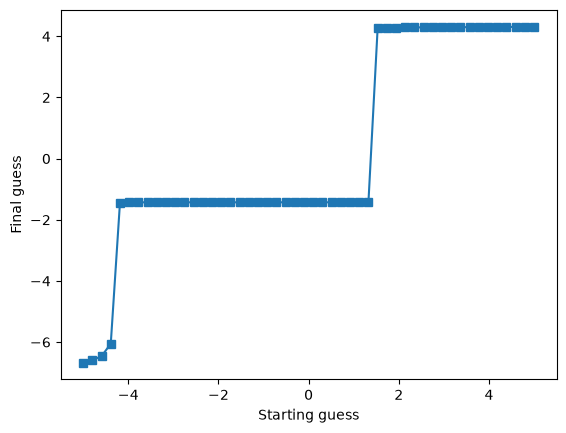

In [37]:
# Select random starting point

startLocations = np.linspace(-5,5,50)
finalRes = np.zeros(len(startLocations))

# Set up parameters

learning_rate = 0.01
training_epochs = 1000

for idx,localmin in enumerate(startLocations):
    
    # Run training function    
    for i in range(training_epochs):
        grad = f_dx(localmin)
        localmin = localmin - learning_rate*grad

        # Store results
        finalRes[idx] = localmin

# Ploy results
plt.plot(startLocations,finalRes,'s-')
plt.xlabel('Starting guess')
plt.ylabel('Final guess')

plt.show()

Analysis

The table above runs the traning function starting at specific values defined on startingLocations. Each value then runs the n traning_epochs adn retrusn the localminimum found.

We can say that the experiment found 3 local minimums in the experiments made, these are: 
- -1.4...
- -6.5...
- 4.2...

Which relate specifically to the value of x on the top graph

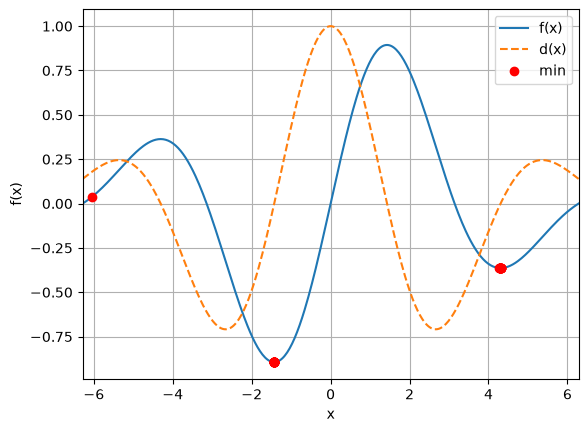

In [40]:
# Ploting found localmins

plt.plot(x,f_fx(x),x,f_dx(x),'--')
# plt.plot(finalRes, f_dx(finalRes),'ro')
plt.plot(finalRes, f_fx(finalRes),'ro')

plt.xlim(x[[0,-1]])
plt.grid()
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend(['f(x)','d(x)','min'])

plt.show()

This gives a easier view of the local minimums found on the experiment

## Experiment 2: Systematically varying the learning rate

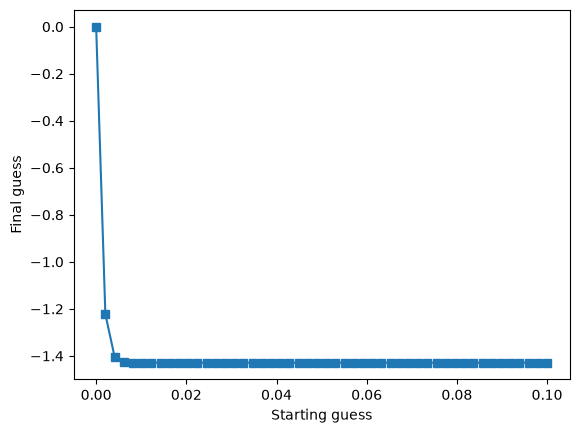

In [42]:
learningRates = np.linspace(1e-10,1e-1,50)
finalRes = np.zeros(len(learningRates))

for idx, learningRate in enumerate(learningRates):

    # Force a localmin
    localmin = 0        
    # Run training function    
    for i in range(training_epochs):
        grad = f_dx(localmin)
        localmin = localmin - learningRate*grad

        # Store results
        finalRes[idx] = localmin

# Ploy results
plt.plot(learningRates,finalRes,'s-')
plt.xlabel('Starting guess')
plt.ylabel('Final guess')

plt.show()


With a small learning rate it struggles to get to the local minimum, the moment the learning rate increases it goes right to -1.4..

## Experiment 3: Interaction between learning rates and training epochs

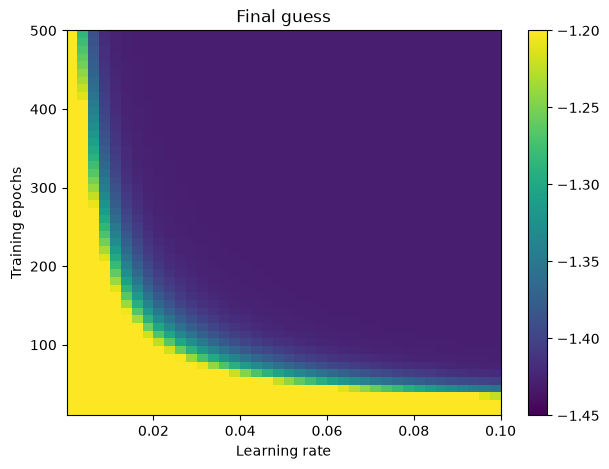

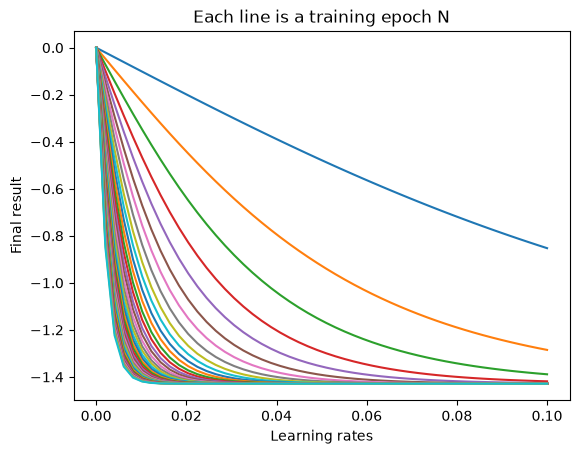

In [76]:

learningRates = np.linspace(1e-10,1e-1,50)
trainingEpochs = np.round(np.linspace(10,500,40))

finalRes = np.zeros((len(learningRates),len(trainingEpochs)))


for Lidx,learningRate in enumerate(learningRates):
    for Tidx, epochs in enumerate(trainingEpochs):
        # Set static localmin (starting value)
        localmin = 0

        for i in range(int(epochs)):
            grad = f_dx(localmin)
            localmin = localmin - learningRate*grad

        # Save result
        finalRes[Lidx,Tidx] = localmin

# Plot results
fix,ax = plt.subplots(figsize=(7,5))

plt.imshow(finalRes,extent=[learningRates[0],learningRates[-1],trainingEpochs[0],trainingEpochs[-1]], aspect='auto',
          origin='lower', vmin=-1.45,vmax=-1.2)

plt.xlabel('Learning rate')
plt.ylabel('Training epochs')

plt.title('Final guess')

plt.colorbar()
plt.show()

plt.plot(learningRates,finalRes)
plt.xlabel('Learning rates')
plt.ylabel('Final result')
plt.title('Each line is a training epoch N')

plt.show()